# Влияние perplexity на двумерную визуализацию t-SNE

**О чём работа.** Бывают данные, в которых каждый объект описан десятками и сотнями чисел — например, рукописная цифра на картинке 8×8 это 64 числа. Нарисовать такие данные нельзя, но можно построить «карту»: каждый объект становится точкой на плоскости, а похожие объекты оказываются рядом. Один из самых популярных способов построить такую карту — алгоритм **t-SNE**. У него есть главная «ручка настройки» — параметр **perplexity**. Мы выясняем, как эта ручка меняет карту.

**План.**
1. Что такое t-SNE и perplexity — простыми словами.
2. Эксперимент 1: рукописные цифры.
3. Эксперимент 2: «свёрнутый лист» (swiss roll).
4. Выводы.

## 1. t-SNE и perplexity простыми словами

**Идея t-SNE.** Для каждой точки алгоритм определяет, кто её ближайшие соседи в исходных данных. Затем он раскладывает точки по плоскости и многократно понемногу сдвигает их: настоящие соседи притягиваются друг к другу, остальные отталкиваются. В итоге получается карта, на которой соседи из исходных данных остаются соседями.

**Работа "на пальцах".** 
В многомерном пространстве строится матрица сходства по многомерному распределению Гаусса
$$
p_{j|i}=\frac{\exp\!\left(-\|x_i-x_j\|^2/2\sigma_i^2\right)}{\sum_{k\neq i}\exp\!\left(-\|x_i-x_k\|^2/2\sigma_i^2\right)} .
$$

$\sigma_i$ - отвечает за дисперсию в каждой точке - чем больше дисперсия, тем больше "вероятность сходства" точек.

Для сравнения с $q_{ij}$ условные вероятности симметризуют: $p_{ij}=\dfrac{p_{j|i}+p_{i|j}}{2n}$, где $n$ — число точек.

Затем точки переносятся в маломерное (например 2D) пространство и строится матрица сходства по распределению Коши (в нотации метода - Стьюдента с 1 степенью свободы)

$$
q_{ij} = \frac{\dfrac{1}{1 + \|y_i - y_j\|^2}}{\displaystyle\sum_k \sum_{l \neq k} \dfrac{1}{1 + \|y_k - y_l\|^2}}.
$$

Далее градиентным спуском точки перемещаются так, чтобы "расхождения" матриц было минимальным.

Вместо задания $\sigma_i$ для всех точек вводят общий гиперпараметр "Perplexity".

**Perplexity** — это мера количества соседей, которых учитывает каждая точка. Грубо говоря, число соседей, на которых алгоритм смотрит при расчёте.
- Маленькое значение: каждая точка смотрит только на самых близких соседей.
- Большое значение: каждая точка учитывает широкую окрестность.

По этому параметру для каждой точки подбирается $\sigma_i$ так, чтобы эффективное число соседей $2^{H}$ (где $H$ — энтропия распределения $p_{\cdot|i}$) равнялось заданному perplexity.

Perplexity должна быть меньше числа точек. В экспериментах мы меняем **только её**, все остальные настройки одинаковы (в том числе стартовая раскладка точек, поэтому результат повторяется при каждом запуске).

**Как читать картинку t-SNE** (это важно для всей работы):
-  Точки, которые рядом на карте, действительно были похожи в исходных данных.
-  Точки, которые далеко на карте, могут быть похожи в исходных данных. (возможны дыры)
-  Размеры групп, расстояния между далёкими группами и направления осей **не имеют надёжного смысла**.


In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

from sklearn.datasets import load_digits, make_swiss_roll
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 65
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11})

def savefig(name):
    plt.savefig(FIG_DIR / name, bbox_inches="tight", dpi=130)

def run_tsne(data, perplexity):
    # t-SNE с фиксированными настройками; меняется только perplexity.
    model = TSNE(n_components=2, perplexity=perplexity, init="pca",
                 learning_rate="auto", max_iter=1000, random_state=SEED)
    start = time.time()
    emb = model.fit_transform(data)
    return emb, time.time() - start

n_components=2 означает, что точки будут укладываться на двумерное пространство (плоскость).

init="pca" означает, что точки будут укладываться на плоскость по методу главных компонент.

## 2. Эксперимент 1: рукописные цифры

**Данные.** Набор `digits` из библиотеки scikit-learn: 1797 изображений рукописных цифр 0–9 размером 8×8 пикселей. Каждое изображение — это 64 числа (яркость пикселей), то есть точка в 64-мерном пространстве. Вот примеры:

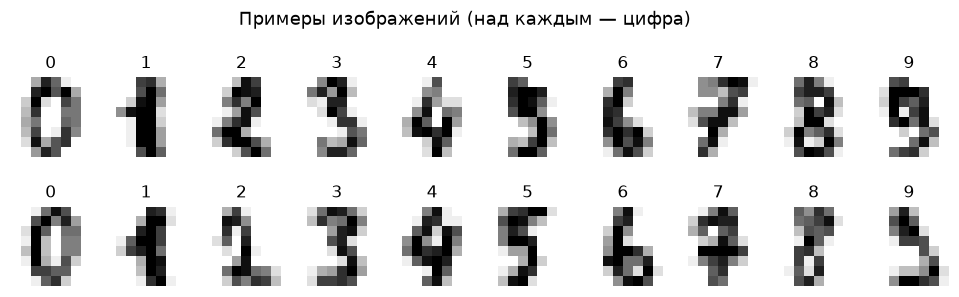

In [2]:
X, y = load_digits(return_X_y=True)

fig, axes = plt.subplots(2, 10, figsize=(11, 2.8))
for ax, img, label in zip(axes.ravel(), X[:20], y[:20]):
    ax.imshow(img.reshape(8, 8), cmap="gray_r")
    ax.set_title(str(label)); ax.axis("off")
fig.suptitle("Примеры изображений (над каждым — цифра)", y=1.05)
savefig("01_digits_examples.png")
plt.show()

Ясно, что алгоритму t-SNE не сообщается точная цифра, — он видит только 64 числа. Цветом мы раскрашиваем точки уже после расчёта, чтобы проверить результат: если t-SNE сработал хорошо, одинаковые цифры должны собраться вместе.

Строим карту для восьми значений perplexity — от 2 до 500.

In [3]:
PERPLEXITIES = [2, 5, 10, 30, 50, 100, 300, 500]
embeddings, times = {}, {}
for p in PERPLEXITIES:
    embeddings[p], times[p] = run_tsne(X, p)
    print(f"perplexity = {p:>3}: {times[p]:5.1f} с")

perplexity =   2:   2.1 с
perplexity =   5:   2.2 с
perplexity =  10:   2.3 с
perplexity =  30:   2.7 с
perplexity =  50:   3.5 с
perplexity = 100:   5.0 с
perplexity = 300:   8.7 с
perplexity = 500:  11.5 с


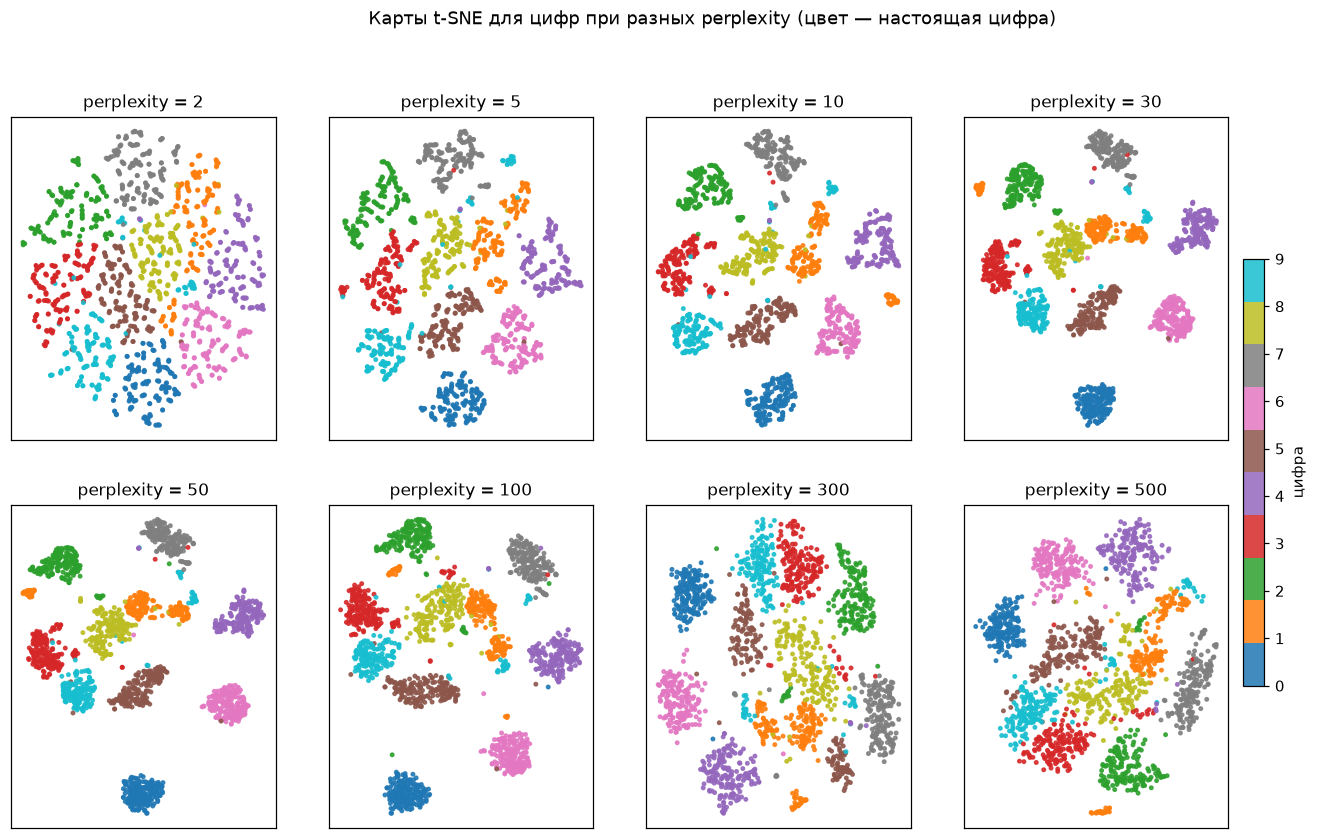

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8.4))
for ax, p in zip(axes.ravel(), PERPLEXITIES):
    Z = embeddings[p]
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=y, cmap="tab10", s=5, alpha=0.85)
    ax.set_title(f"perplexity = {p}")
    ax.set_xticks([]); ax.set_yticks([])
cbar = fig.colorbar(sc, ax=axes, ticks=range(10), shrink=0.6, pad=0.01)
cbar.set_label("цифра")
fig.suptitle("Карты t-SNE для цифр при разных perplexity (цвет — настоящая цифра)", y=0.995)
savefig("02_digits_grid.png")
plt.show()

### Что видно на картинках

Точки на всех восьми картах — одни и те же 1797 цифр, меняется только perplexity.

- **perplexity = 2.** Почти однородное облако. Цифры уже занимают свои области, но чётких групп нет: каждая точка смотрит всего на 2–3 соседей, и карта получается «рассыпанной».
- **perplexity = 5.** Группы появились, но многие из них рассыпаются на мелкие кусочки.
- **perplexity = 10…50.** Чёткие компактные кластеры, каждому соответствует своя цифра. Это самые «читаемые» карты. (Цифра 1, оранжевый цвет, здесь разбита на несколько островков — возможно, из-за разных начертаний единицы; мы это не проверяли.)
- **perplexity = 100…500.** Кластеры «диффундируют» друг к другу; при 300–500 соседние группы касаются и частично перемешиваются.

Получается последовательность: **кучка разбросанных точек → чёткие кластеры → кластеры «диффундируют» друг в друга**.

### Как измерить «качество» карты

Глазами видно многое, но хочется и числа. Мы используем **две простые проверки**:

1. **Верные соседи** — насколько карта сохраняет соседство. Для каждой точки берём 10 её ближайших соседей на карте и 10 ближайших соседей в исходных 64-мерных данных и смотрим, какая доля совпала. 1 — все соседи сохранены, 0 — ни одного.
2. **Чистота** — насколько на карте «вместе» оказываются одинаковые цифры. Для каждой точки смотрим на 5 ближайших соседей *на карте*; если большинство из них той же цифры, что и сама точка, то точка «чистая». Чистота — доля таких точек.

Чтобы числа было с чем сравнивать, добавим два **контрольных варианта**: «случайные точки» (карта без всякой логики) и обычную проекцию **PCA** — простой классический способ сжать данные до двух чисел без t-SNE.

In [5]:
def neighbors(data, k):
    # Индексы k ближайших соседей каждой точки (саму точку не считаем).
    nn = NearestNeighbors(n_neighbors=k + 1).fit(data)
    return nn.kneighbors(data, return_distance=False)[:, 1:]

def true_neighbors_score(data, emb, k=10):
    # Верные соседи: доля совпавших соседей в исходных данных и на карте.
    a, b = neighbors(data, k), neighbors(emb, k)
    return float(np.mean([len(set(a[i]) & set(b[i])) / k for i in range(len(data))]))

def purity_score(emb, labels, k=5):
    # Чистота: у какой доли точек большинство соседей на карте той же цифры.
    nb = neighbors(emb, k)
    hits = [np.bincount(labels[nb[i]]).argmax() == labels[i] for i in range(len(labels))]
    return float(np.mean(hits))

rng = np.random.default_rng(SEED)
baselines = {
    "случайные точки": rng.normal(size=(len(X), 2)),
    "PCA (без t-SNE)": PCA(n_components=2).fit_transform(X),
}

rows = []
for p in PERPLEXITIES:
    rows.append({"вариант": f"t-SNE, perplexity={p}", "perplexity": p,
                 "верные соседи": true_neighbors_score(X, embeddings[p]),
                 "чистота": purity_score(embeddings[p], y),
                 "время, с": times[p]})
for name, Z in baselines.items():
    rows.append({"вариант": name, "perplexity": np.nan,
                 "верные соседи": true_neighbors_score(X, Z),
                 "чистота": purity_score(Z, y), "время, с": np.nan})

table = pd.DataFrame(rows).set_index("вариант")
table.drop(columns="perplexity").to_csv("results_digits.csv")
table.drop(columns="perplexity").round(3)

,верные соседи,чистота,"время, с"
вариант,,,
"t-SNE, perplexity=2",0.486,0.987,2.117
"t-SNE, perplexity=5",0.543,0.989,2.164
"t-SNE, perplexity=10",0.574,0.990,2.323
"t-SNE, perplexity=30",0.585,0.989,2.727
"t-SNE, perplexity=50",0.577,0.988,3.501
"t-SNE, perplexity=100",0.541,0.984,4.987
"t-SNE, perplexity=300",0.477,0.978,8.678
"t-SNE, perplexity=500",0.422,0.967,11.537
случайные точки,0.006,0.095,NaN


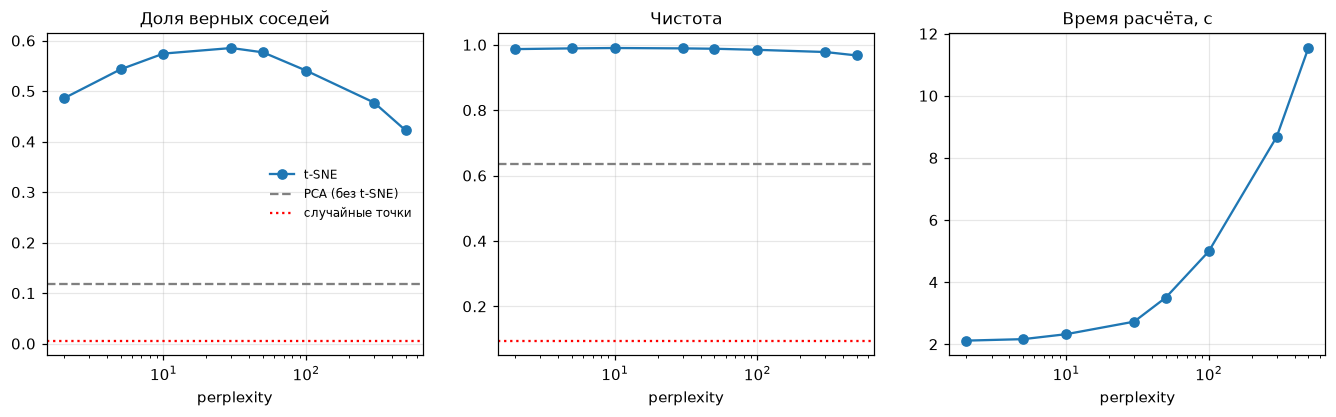

In [6]:
tsne_part = table.dropna(subset=["perplexity"])
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, title in zip(axes, ["верные соседи", "чистота", "время, с"],
                          ["Доля верных соседей", "Чистота", "Время расчёта, с"]):
    ax.plot(tsne_part["perplexity"], tsne_part[col], "o-", label="t-SNE")
    if col != "время, с":
        ax.axhline(table.loc["PCA (без t-SNE)", col], color="gray", ls="--", label="PCA (без t-SNE)")
        ax.axhline(table.loc["случайные точки", col], color="red", ls=":", label="случайные точки")
    ax.set_xscale("log"); ax.set_xlabel("perplexity"); ax.set_title(title); ax.grid(alpha=0.3)
axes[0].legend(frameon=False, fontsize=8)
savefig("03_digits_metrics.png")
plt.show()

### Что показывают числа

- **Верные соседи** имеют явный максимум: **почти 0.6 при perplexity 10–50**. Для сравнения: у PCA чуть больше 0.1, у случайных точек около 0, то есть t-SNE сохраняет соседей примерно в 5 раз лучше обычной проекции. То, что получили не 1 — нормально: соседство из 64-мерного пространства не может целиком уместиться на плоскости.
- **Чистота** почти не меняется: колеблется около 1 при всех perplexity (у PCA 0.6, у случайных точек 0.1). Значит, точки одной цифры остаются рядом друг с другом, а ухудшается другое — картина «кто чей сосед внутри окрестности». Эта проверка слишком грубая, чтобы заметить расплывание кластеров; небольшое снижение всё же видно.
- **Время** растёт с 7 до 34 секунд, то есть примерно в 5 раз.

**Итог эксперимента 1.** Оба края диапазона (2 и 500) хуже середины, а при perplexity 10–50 результат близок к лучшему. Различия внутри этого диапазона малы; так как мы считали по одному запуску, утверждать, что какое-то одно значение лучше другого, нельзя.

## 3. Эксперимент 2: «свёрнутый лист» (swiss roll)

Цифры — «сложный» пример: данные там сами собой разбиваются на группы. Для второго эксперимента возьмём другие данные: плоский лист, свёрнутый в рулон (как рулет). Точки лежат в 3D, но по сути это двумерный лист. Цвет показывает положение точки **вдоль листа**.

Если бы t-SNE идеально «развернул» рулон, мы увидели бы плоскую полосу с плавным переходом цвета. Вот как выглядит рулон и «правильный ответ» — его развёртка:

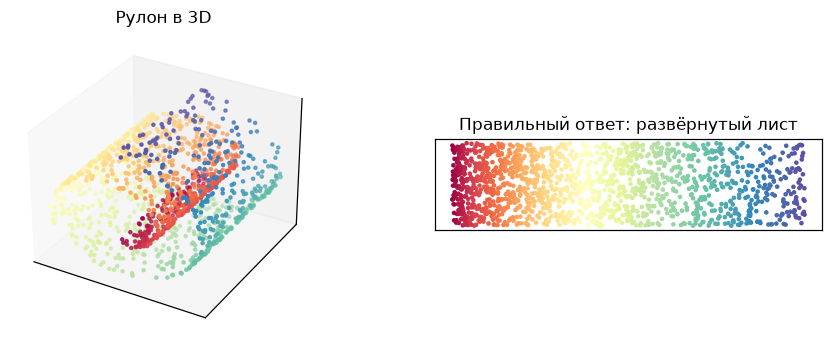

In [7]:
Xs, t = make_swiss_roll(n_samples=1500, noise=0.05, random_state=SEED)

# «Правильная» развёртка: положение вдоль листа (длина дуги спирали) и высота.
arc = 0.5 * (t * np.sqrt(1 + t**2) + np.arcsinh(t))
flat = np.c_[arc, Xs[:, 1]]

fig = plt.figure(figsize=(10, 3.6))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.scatter(Xs[:, 0], Xs[:, 1], Xs[:, 2], c=t, cmap="Spectral", s=4)
ax.set_title("Рулон в 3D"); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
ax2 = fig.add_subplot(1, 2, 2)
ax2.scatter(flat[:, 0], flat[:, 1], c=t, cmap="Spectral", s=4)
ax2.set_title("Правильный ответ: развёрнутый лист"); ax2.set_xticks([]); ax2.set_yticks([])
ax2.set_aspect("equal")
savefig("04_swiss_roll_truth.png")
plt.show()

Построим карты t-SNE для восьми значений perplexity. Помимо картинки посчитаем:
- **верные соседи** — как в первом эксперименте (по 10 ближайшим соседям в исходных 3D-данных);
- **доля разрывов** — какая доля пар «соседей в рулоне» на карте оказалась далеко друг от друга (в 4 раза дальше обычного расстояния между соседями на этой карте). Это число показывает, насколько сильно t-SNE «порвал» лист.

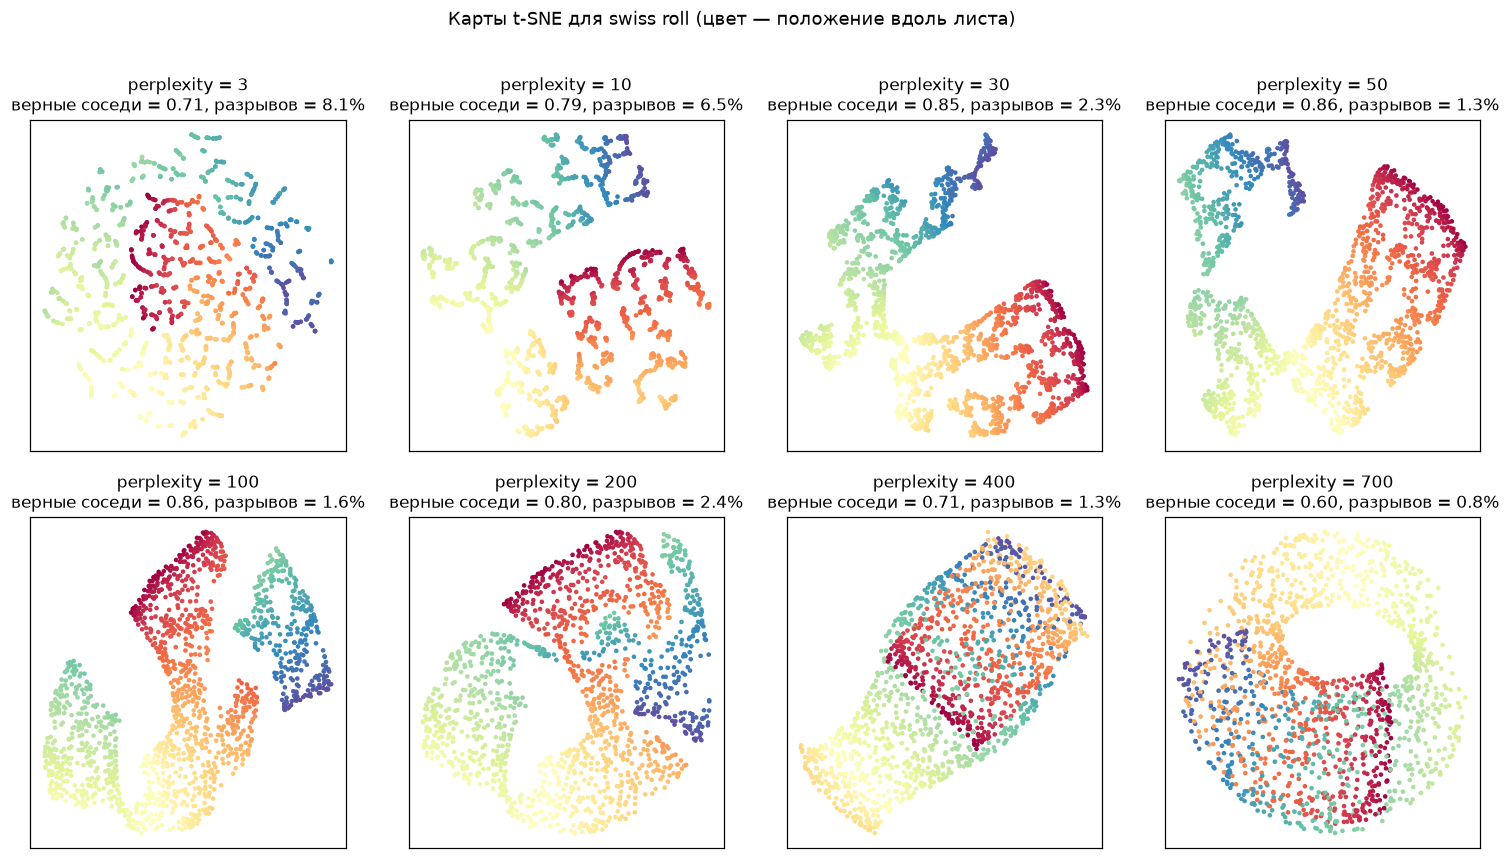

,верные соседи,доля разрывов
perplexity,,
3,0.713,0.081
10,0.790,0.065
30,0.854,0.023
50,0.864,0.013
100,0.864,0.016
200,0.804,0.024
400,0.706,0.013
700,0.599,0.008


In [8]:
def broken_links(data, emb, k=10, factor=4):
    # Находит пары соседей из исходных данных, которые на карте оказались далеко.
    nb = neighbors(data, k)
    src = np.repeat(np.arange(len(data)), k)
    dst = nb.ravel()
    dist = np.linalg.norm(emb[src] - emb[dst], axis=1)
    broken = dist > factor * np.median(dist)
    return broken.mean(), src[broken], dst[broken]

SWISS_PERPLEXITIES = [3, 10, 30, 50, 100, 200, 400, 700]
swiss_emb, swiss_rows = {}, []
for p in SWISS_PERPLEXITIES:
    Z, sec = run_tsne(Xs, p)
    swiss_emb[p] = Z
    share, _, _ = broken_links(Xs, Z)
    swiss_rows.append({"perplexity": p,
                       "верные соседи": true_neighbors_score(Xs, Z),
                       "доля разрывов": share})
swiss_table = pd.DataFrame(swiss_rows).set_index("perplexity")

fig, axes = plt.subplots(2, 4, figsize=(17, 8.6))
for ax, p in zip(axes.ravel(), SWISS_PERPLEXITIES):
    Z = swiss_emb[p]
    ax.scatter(Z[:, 0], Z[:, 1], c=t, cmap="Spectral", s=4)
    r = swiss_table.loc[p]
    ax.set_title(f"perplexity = {p}\nверные соседи = {r['верные соседи']:.2f}, разрывов = {r['доля разрывов']:.1%}")
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Карты t-SNE для swiss roll (цвет — положение вдоль листа)", y=0.995)
savefig("05_swiss_roll_grid.png")
plt.show()
swiss_table.to_csv("results_swiss_roll.csv")
swiss_table.round(3)

### Что видно на swiss roll

- **perplexity = 3.** Много коротких «ниточек», перемешанных между собой: соседние по цвету точки рядом, но общий порядок вдоль листа потерян.
- **perplexity = 10.** Нити собираются в несколько групп, порядок цветов уже угадывается.
- **perplexity = 30…100.** Лучший результат (верные соседи достигают максимума, ≈ 0.86): лист в основном развёрнут, цвет плавно меняется вдоль кусков. Но полной полосы нет: при 30 лист изогнут, а при 50–100 **разорван на несколько частей**.
- **perplexity = 200.** Куски крупнее, но их взаимное расположение сильно отличается от настоящей развёртки.
- **perplexity = 400.** Разные цвета (красный, синий, оранжевый) перемешаны в одной области. Вероятное объяснение: при такой широкой окрестности в неё попадают точки соседних витков рулона, которые в 3D лежат близко, хотя вдоль листа далеки.
- **perplexity = 700** (почти половина всех точек). Карта превращается в кольцо, в центре которого слои рулона перемешаны. Результат при таком perplexity сильно зависит от выборки: при другом `SEED` карта вырождалась в бесструктурное облако. Слишком большое perplexity разрушает карту.



### Откуда берутся «дыры»

Посмотрим на разрывы прямо на карте. Для perplexity = 50 соединим чёрными линиями пары точек, которые в рулоне были соседями, а на карте оказались далеко друг от друга.

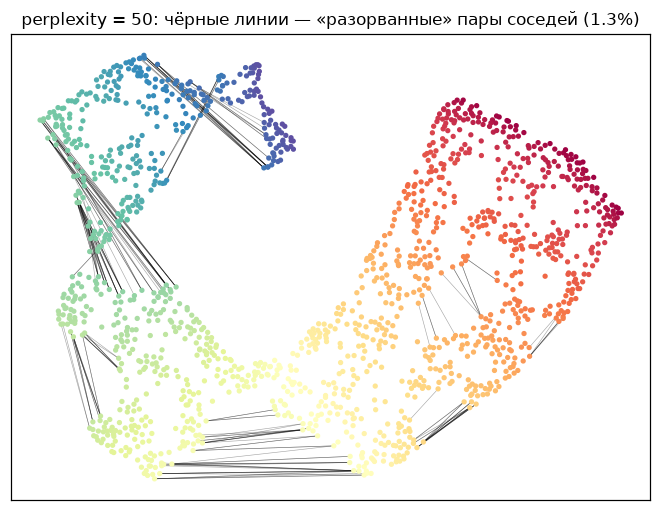

In [9]:
p = 50
Z = swiss_emb[p]
share, src, dst = broken_links(Xs, Z)
segments = np.stack([Z[src], Z[dst]], axis=1)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(Z[:, 0], Z[:, 1], c=t, cmap="Spectral", s=6, zorder=2)
ax.add_collection(LineCollection(segments, colors="black", linewidths=0.4, alpha=0.35, zorder=1))
ax.set_title(f"perplexity = {p}: чёрные линии — «разорванные» пары соседей ({share:.1%})")
ax.set_xticks([]); ax.set_yticks([])
savefig("06_swiss_roll_breaks.png")
plt.show()

Главный пучок чёрных линий идёт через самый заметный промежуток слева — там, где цвет переходит от светло-зелёного к бирюзовому (тёмно-зелёному). Остальные линии короткие и лежат внутри кусков.

**Почему так происходит.** t-SNE старается сохранить *соседей*, но не обязан сохранять лист *целым*. По-видимому, алгоритму проще «разрезать» рулон в одном-двух местах, чем растянуть его в цельную полосу. Поэтому пустой промежуток — следствие разреза, а не свойство данных: в самом рулоне точки в этом месте лежат так же плотно, как везде. Место разреза зависит от perplexity: на карте при perplexity = 100 основной разрез проходит в другом месте (между красно-оранжевой и сине-зелёной частями).

(более того у scikit-learn наблюдается такой эффект https://scikit-learn.org/stable/auto_examples/manifold/plot_swissroll.html)

**Итого.** Внутри каждого куска порядок цветов верен, и ему можно доверять. Промежуткам между кусками и тому, насколько далеко куски друг от друга, доверять нельзя. Для «честной» развёртки подобных листов обычно используют другие методы — t-SNE имеет другую цель: он хорошо выделяет компактные группы.




## 4. Выводы

1. **Perplexity — это «сколько соседей учитывает каждая точка».** Она задаёт масштаб, на котором t-SNE смотрит на данные.
2. **Слишком маленькая** (2–5 на цифрах, 3–10 на рулоне): карта «рассыпается» на мелкие фрагменты; случайные уплотнения выглядят как отдельные группы.
3. **Слишком большая** (300–500 на цифрах, 400–700 на рулоне): кластеры расплываются и склеиваются, соседство сохраняется хуже, расчёт идёт примерно в 5 раз дольше.
4. **Разумная середина — примерно 10–50** в обоих экспериментах (1500–1800 точек); типичное стартовое значение — около 30.

**Ограничения работы.** Два набора данных, по одному расчёту на каждое значение. Результат t-SNE зависит от стартовой раскладки и случайности; в этой работе мы этого отдельно не исследовали. Кроме того, при смене `SEED` меняется и выборка рулона, а картины при больших perplexity (400–700) заметно отличаются, поэтому выводы о крайних значениях носят качественный характер. Метрики грубые (особенно «чистота»). Рекомендованный диапазон относится к данным такого размера (1,5–1,8 тыс. точек); для других размеров его нужно проверять.